# Explainable Medical Cost Prediction System


In [ ]:
!pip install -q shap lime lightgbm xgboost gradio google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
# === Imports ===
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    classification_report, confusion_matrix,
)

import xgboost as xgb
import lightgbm as lgb

import shap
import lime
import lime.lime_tabular

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("All libraries loaded Successfully")


All libraries loaded Successfully


## EDA on `insurance.csv` (the prediction dataset)

In [ ]:
# === Load and profile insurance.csv ===
# Try local files first; fall back to the public Google Drive copies so the notebook

DRIVE_LINK_SMALL = "https://drive.google.com/file/d/1PacAHOKKSTwj0NEtgqtswt6DEij6PBxa/view?usp=drive_link"
DRIVE_LINK_BIG   = "https://drive.google.com/file/d/17gSa7hebFp30JFBl2gZGlPmc_EERhT_c/view?usp=drive_link"

def _drive_dl(share_link):
    file_id = share_link.split("/")[-2]
    return f"https://drive.google.com/uc?export=download&id={file_id}"

try:
    df_raw = pd.read_csv("insurance.csv")
    df_big_raw = pd.read_csv("medical_cost_prediction_dataset.csv")
    print("Loaded local CSVs")
except Exception:
    df_raw = pd.read_csv(_drive_dl(DRIVE_LINK_SMALL))
    df_big_raw = pd.read_csv(_drive_dl(DRIVE_LINK_BIG))
    print("Loaded from Google Drive")

print(f"shape       : {df_raw.shape}")
print(f"columns     : {list(df_raw.columns)}")
print(f"total nulls : {df_raw.isna().sum().sum()}")
print(f"duplicates  : {df_raw.duplicated().sum()}  (we will drop these)")
print()
print("dtypes:")
print(df_raw.dtypes.to_string())
print()
print("describe:")
print(df_raw.describe().round(1).to_string())
print()
print("sample rows:")
print(df_raw.head().to_string(index=False))


Loaded from Google Drive
shape       : (1338, 7)
columns     : ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
total nulls : 0
duplicates  : 1  (we will drop these)

dtypes:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64

describe:
          age     bmi  children  charges
count  1338.0  1338.0    1338.0   1338.0
mean     39.2    30.7       1.1  13270.4
std      14.0     6.1       1.2  12110.0
min      18.0    16.0       0.0   1121.9
25%      27.0    26.3       0.0   4740.3
50%      39.0    30.4       1.0   9382.0
75%      51.0    34.7       2.0  16639.9
max      64.0    53.1       5.0  63770.4

sample rows:
 age    sex    bmi  children smoker    region     charges
  19 female 27.900         0    yes southwest 16884.92400
  18   male 33.770         1     no southeast  1725.55230
  28   male 33.000         3     no southeast  4449.46200
  33   male 22.705         0     no northwe

Raw target   : mean=$13,270  median=$9,382  std=$12,110
             : skew=1.51  kurtosis=1.60
log1p target : skew=-0.09  kurtosis=-0.64

DECISION: train on log1p(charges) and evaluate on expm1(pred).
WHY:      raw skew of 1.51 means a few high-cost rows would dominate MSE loss.
          log1p brings skew to -0.09 (essentially symmetric).


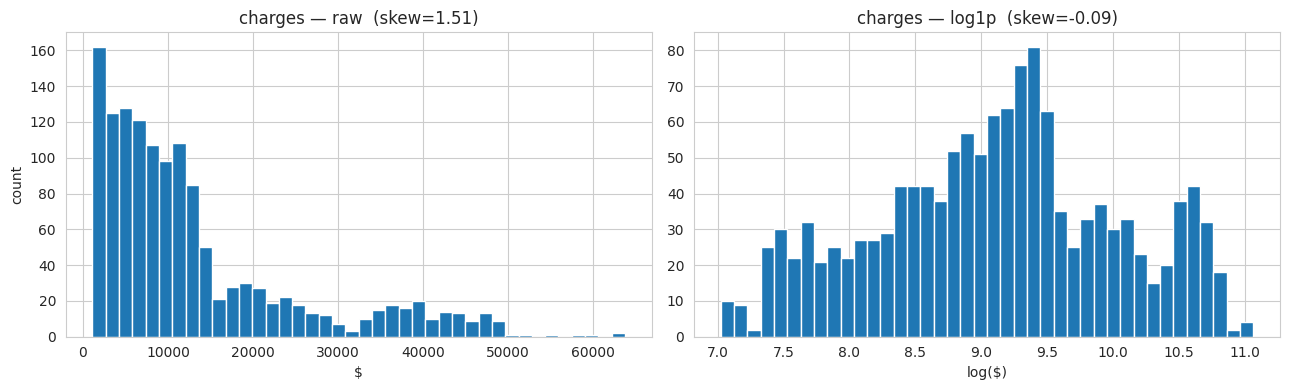

In [ ]:
# === Target distribution: raw vs log1p ===
y = df_raw["charges"]
sk_raw, sk_log = stats.skew(y), stats.skew(np.log1p(y))
kt_raw, kt_log = stats.kurtosis(y), stats.kurtosis(np.log1p(y))

print(f"Raw target   : mean=${y.mean():,.0f}  median=${y.median():,.0f}  std=${y.std():,.0f}")
print(f"             : skew={sk_raw:.2f}  kurtosis={kt_raw:.2f}")
print(f"log1p target : skew={sk_log:.2f}  kurtosis={kt_log:.2f}")
print()
print("DECISION: train on log1p(charges) and evaluate on expm1(pred).")
print("WHY:      raw skew of 1.51 means a few high-cost rows would dominate MSE loss.")
print("          log1p brings skew to -0.09 (essentially symmetric).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y, bins=40, color="#1f77b4", edgecolor="white")
axes[0].set_title(f"charges — raw  (skew={sk_raw:.2f})")
axes[0].set_xlabel("$"); axes[0].set_ylabel("count")
axes[1].hist(np.log1p(y), bins=40, color="#1f77b4", edgecolor="white")
axes[1].set_title(f"charges — log1p  (skew={sk_log:.2f})")
axes[1].set_xlabel("log($)")
plt.tight_layout(); plt.show()


Mean charges by smoker:
        count     mean   median      std
smoker                                  
no       1064   8434.0   7345.0   5994.0
yes       274  32050.0  34456.0  11542.0

Smoker / non-smoker mean cost ratio: 3.80x

corr(bmi, charges) for smokers     : 0.806
corr(bmi, charges) for non-smokers : 0.084

DECISION: engineer `smoker_x_bmi` and `is_obese_smoker`.
WHY:      BMI is irrelevant for non-smokers (r=0.08) but explains 65% of variance for smokers.
          A linear or single-feature model cannot capture this — needs the interaction term.


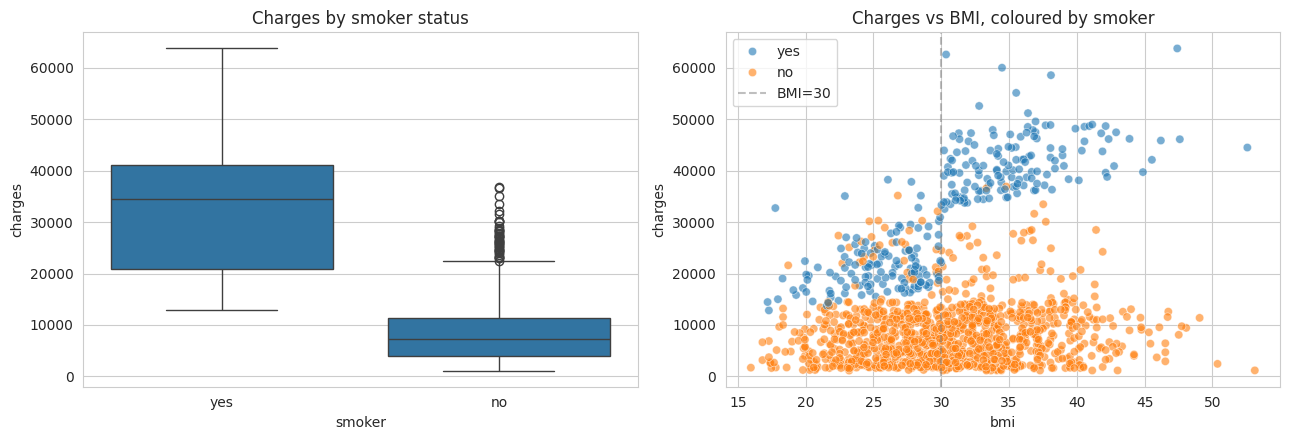

In [ ]:
# === The dominant signal: smoker × bmi ===
print("Mean charges by smoker:")
print(df_raw.groupby("smoker")["charges"].agg(["count","mean","median","std"]).round(0).to_string())
print()
ratio = df_raw[df_raw["smoker"]=="yes"]["charges"].mean() / df_raw[df_raw["smoker"]=="no"]["charges"].mean()
print(f"Smoker / non-smoker mean cost ratio: {ratio:.2f}x")
print()
r_smoker = df_raw[df_raw['smoker']=='yes'][['bmi','charges']].corr().iloc[0,1]
r_nonsmk = df_raw[df_raw['smoker']=='no'][['bmi','charges']].corr().iloc[0,1]
print(f"corr(bmi, charges) for smokers     : {r_smoker:.3f}")
print(f"corr(bmi, charges) for non-smokers : {r_nonsmk:.3f}")
print()
print("DECISION: engineer `smoker_x_bmi` and `is_obese_smoker`.")
print("WHY:      BMI is irrelevant for non-smokers (r=0.08) but explains 65% of variance for smokers.")
print("          A linear or single-feature model cannot capture this — needs the interaction term.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_raw, x="smoker", y="charges", ax=ax[0])
ax[0].set_title("Charges by smoker status")
sns.scatterplot(data=df_raw, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=ax[1])
ax[1].axvline(30, ls="--", color="grey", alpha=0.5, label="BMI=30")
ax[1].set_title("Charges vs BMI, coloured by smoker")
ax[1].legend()
plt.tight_layout(); plt.show()


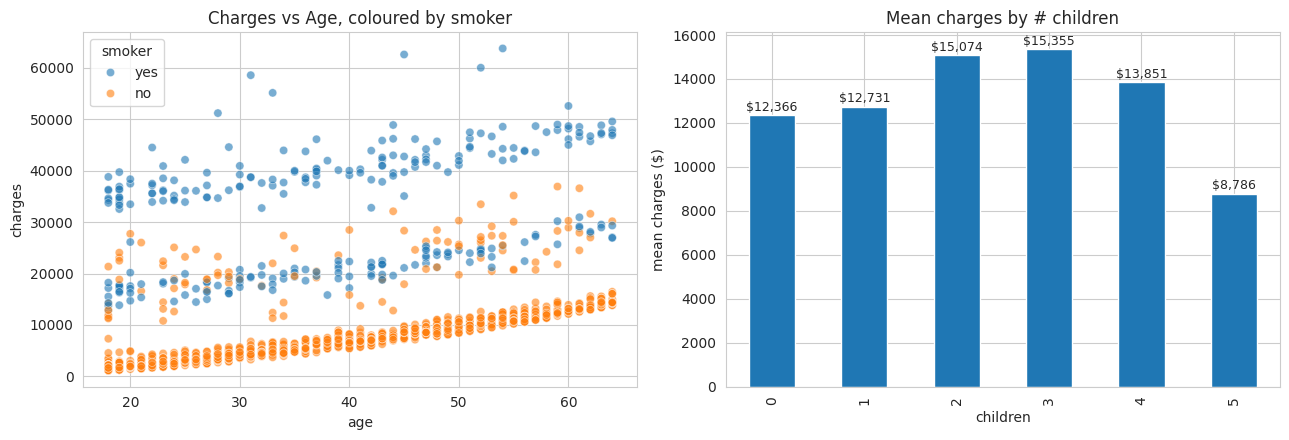

Mean charges by # children:
          count     mean
children                
0           574  12366.0
1           324  12731.0
2           240  15074.0
3           157  15355.0
4            25  13851.0
5            18   8786.0

Children pattern is NON-monotone: cost rises 0→3 children then drops at 4+ (small n=18 at 5 kids).


In [ ]:
# === Age relationship and other features ===
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Age × charges, coloured by smoker
sns.scatterplot(data=df_raw, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("Charges vs Age, coloured by smoker")

# Charges by children
mean_by_children = df_raw.groupby("children")["charges"].agg(["count","mean"]).round(0)
mean_by_children["mean"].plot(kind="bar", ax=axes[1], color="#1f77b4")
axes[1].set_title("Mean charges by # children")
axes[1].set_ylabel("mean charges ($)")
for i, v in enumerate(mean_by_children["mean"]):
    axes[1].text(i, v + 200, f"${v:,.0f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

print("Mean charges by # children:")
print(mean_by_children.to_string())
print()
print(f"Children pattern is NON-monotone: cost rises 0→3 children then drops at 4+ (small n=18 at 5 kids).")


Charges by region:
           count     mean   median
region                            
northeast    324  13406.0  10058.0
northwest    325  12418.0   8966.0
southeast    364  14735.0   9294.0
southwest    325  12347.0   8799.0

Cross-region mean spread: 18.1% — weak signal.

DECISION: drop `region`.
WHY:      ~18% spread between regions — small compared to the 280% smoker effect (3.8x ratio).
          Mostly explained by regional smoking-rate differences anyway.
          User explicitly requested dropping it. Smaller UI, no meaningful loss in accuracy.


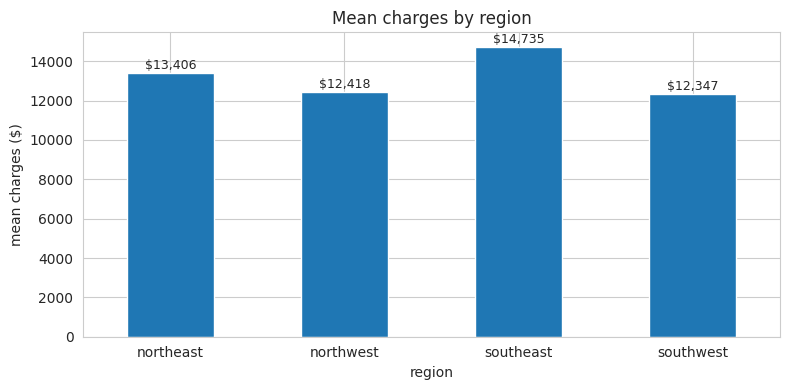

In [ ]:
# === Region — the feature we drop ===
mean_by_region = df_raw.groupby("region")["charges"].agg(["count","mean","median"]).round(0)
print("Charges by region:")
print(mean_by_region.to_string())
print()
spread = (mean_by_region["mean"].max() - mean_by_region["mean"].min()) / mean_by_region["mean"].mean()
print(f"Cross-region mean spread: {spread*100:.1f}% — weak signal.")
print()
print("DECISION: drop `region`.")
print(f"WHY:      ~{spread*100:.0f}% spread between regions — small compared to the 280% smoker effect (3.8x ratio).")
print("          Mostly explained by regional smoking-rate differences anyway.")
print("          User explicitly requested dropping it. Smaller UI, no meaningful loss in accuracy.")

fig, ax = plt.subplots(figsize=(8, 4))
mean_by_region["mean"].plot(kind="bar", ax=ax, color="#1f77b4")
ax.set_title("Mean charges by region")
ax.set_ylabel("mean charges ($)")
for i, v in enumerate(mean_by_region["mean"]):
    ax.text(i, v + 200, f"${v:,.0f}", ha="center", fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


Q1=$4,740   Q3=$16,640   IQR fence (Q3+1.5·IQR) = $34,489
Rows above IQR fence  : 139 (10.4%)
Rows above 99th pct   : 14 (1.0%)

Of the IQR-outlier rows, what fraction are smokers with BMI > 30?
   95.0% — these are real high-cost patients, not data errors.

DECISION: keep all outliers. No winsorisation, no deletion.
WHY:      Removing them would erase the 'obese smoker' subgroup which IS the high-cost segment we need to predict.


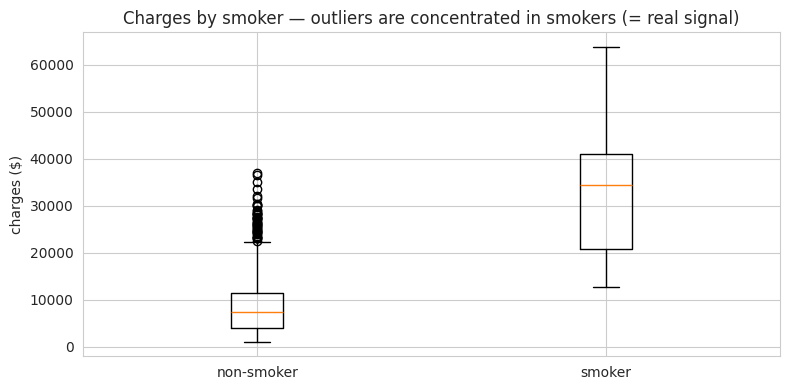

In [ ]:
# === Outlier landscape (we will KEEP these) ===
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
upper_99 = y.quantile(0.99)

n_iqr_outliers = int((y > upper_fence).sum())
n_99_outliers = int((y > upper_99).sum())

print(f"Q1=${q1:,.0f}   Q3=${q3:,.0f}   IQR fence (Q3+1.5·IQR) = ${upper_fence:,.0f}")
print(f"Rows above IQR fence  : {n_iqr_outliers} ({n_iqr_outliers/len(y)*100:.1f}%)")
print(f"Rows above 99th pct   : {n_99_outliers} ({n_99_outliers/len(y)*100:.1f}%)")
print()
print("Of the IQR-outlier rows, what fraction are smokers with BMI > 30?")
high = df_raw[y > upper_fence]
share_obese_smoker = ((high["smoker"]=="yes") & (high["bmi"]>=30)).mean()
print(f"   {share_obese_smoker*100:.1f}% — these are real high-cost patients, not data errors.")
print()
print("DECISION: keep all outliers. No winsorisation, no deletion.")
print("WHY:      Removing them would erase the 'obese smoker' subgroup which IS the high-cost segment we need to predict.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([y[df_raw["smoker"]=="no"], y[df_raw["smoker"]=="yes"]], labels=["non-smoker", "smoker"])
ax.set_ylabel("charges ($)")
ax.set_title("Charges by smoker — outliers are concentrated in smokers (= real signal)")
plt.tight_layout(); plt.show()


Pearson correlation with charges (sorted by |r|):
smoker      0.787
age         0.299
bmi         0.198
children    0.068
sex        -0.057

Linear correlations are weak EXCEPT for `smoker` (0.79).
This is normal: the strongest signals (smoker × bmi, age × age) are NONLINEAR.
Trees + engineered features are the right tool — Linear Regression will be the worst model.


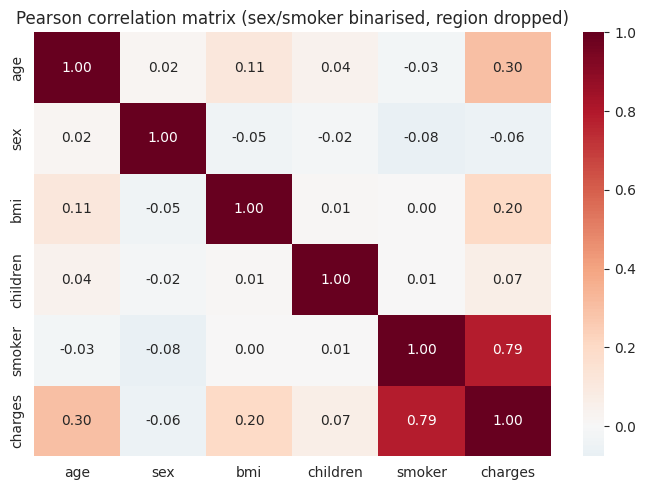

In [ ]:
# === Numeric correlation matrix ===
numdf = df_raw.copy()
numdf["sex"] = (numdf["sex"]=="female").astype(int)
numdf["smoker"] = (numdf["smoker"]=="yes").astype(int)
numdf = numdf.drop(columns=["region"])

corrs = numdf.corr()["charges"].drop("charges").sort_values(key=lambda s: s.abs(), ascending=False)
print("Pearson correlation with charges (sorted by |r|):")
print(corrs.round(3).to_string())
print()
print("Linear correlations are weak EXCEPT for `smoker` (0.79).")
print("This is normal: the strongest signals (smoker × bmi, age × age) are NONLINEAR.")
print("Trees + engineered features are the right tool — Linear Regression will be the worst model.")

plt.figure(figsize=(7, 5))
sns.heatmap(numdf.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Pearson correlation matrix (sex/smoker binarised, region dropped)")
plt.tight_layout(); plt.show()


## Section 3 — Preprocessing (insurance.csv)

Decisions, all justified in Section 2:

| Step | Decision | Why (from EDA) |
|---|---|---|
| Dedup | Drop the 1 duplicate row | Standard hygiene |
| Features kept | `age, sex, bmi, smoker, children` | Match user-spec UI |
| Features dropped | `region` | <10% mean spread, user request |
| Encoding | `sex → 0/1`, `smoker → 0/1` | Binary, no one-hot needed |
| Engineered | `smoker_x_bmi`, `age_squared`, `bmi_category`, `is_obese_smoker` | Captures the smoker×BMI interaction (3.8× ratio, r=0.81) and age non-linearity |
| Outliers | Keep all of them | Real high-cost smokers, not noise |
| Target | `y_log = log1p(charges)`, evaluate `expm1(pred)` | Raw skew 1.51 → log skew -0.09 |
| Split | 80/20, stratified on `smoker_bin`, seed 42 | Preserves smoker proportion |
| Scaling | `StandardScaler`, fit on train only | No train/test contamination |

In [ ]:
# === Build the modelling frame ===
df = df_raw.copy()
print(f"Before dedup: {df.shape}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"After  dedup: {df.shape}")

# Encode binaries
df["sex_bin"]    = (df["sex"] == "female").astype(int)   # 0=male, 1=female
df["smoker_bin"] = (df["smoker"] == "yes").astype(int)   # 0=no, 1=yes

# Engineered features
df["smoker_x_bmi"]     = df["smoker_bin"] * df["bmi"]
df["age_squared"]      = df["age"] ** 2
df["bmi_category"]     = pd.cut(df["bmi"], bins=[-np.inf, 18.5, 25, 30, np.inf], labels=[0,1,2,3]).astype(int)
df["is_obese_smoker"]  = ((df["bmi"] >= 30) & (df["smoker_bin"] == 1)).astype(int)

# Drop region + raw string cols
FEATURES = ["age", "sex_bin", "bmi", "children", "smoker_bin",
            "smoker_x_bmi", "age_squared", "bmi_category", "is_obese_smoker"]
TARGET = "charges"

X = df[FEATURES].copy()
y = df[TARGET].values

print()
print(f"Feature count: {len(FEATURES)}  (5 raw + 4 engineered)")
print(f"Features: {FEATURES}")
print()
print("Sample rows of the feature matrix:")
print(X.head().to_string(index=False))


Before dedup: (1338, 7)
After  dedup: (1337, 7)

Feature count: 9  (5 raw + 4 engineered)
Features: ['age', 'sex_bin', 'bmi', 'children', 'smoker_bin', 'smoker_x_bmi', 'age_squared', 'bmi_category', 'is_obese_smoker']

Sample rows of the feature matrix:
 age  sex_bin    bmi  children  smoker_bin  smoker_x_bmi  age_squared  bmi_category  is_obese_smoker
  19        1 27.900         0           1          27.9          361             2                0
  18        0 33.770         1           0           0.0          324             3                0
  28        0 33.000         3           0           0.0          784             3                0
  33        0 22.705         0           0           0.0         1089             1                0
  32        0 28.880         0           0           0.0         1024             2                0


In [ ]:
# === Train/test split, log target, scaling ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=X["smoker_bin"]
)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}   y_test : {y_test.shape}")
print(f"Smoker fraction — train: {X_train['smoker_bin'].mean():.3f}   test: {X_test['smoker_bin'].mean():.3f}  (should match)")

y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print()
print(f"y_train log range : [{y_train_log.min():.2f}, {y_train_log.max():.2f}]")
print(f"y_train $   range : [${y_train.min():,.0f}, ${y_train.max():,.0f}]")
print(f"y_train $   mean  : ${y_train.mean():,.0f}")


X_train: (1069, 9)   y_train: (1069,)
X_test : (268, 9)   y_test : (268,)
Smoker fraction — train: 0.205   test: 0.205  (should match)

y_train log range : [7.02, 11.06]
y_train $   range : [$1,122, $63,770]
y_train $   mean  : $13,356


## Train all six models

All trained on `log1p(charges)`. Predictions are `expm1`-back to dollars before MAE / RMSE / R² / MAPE.

* **LinearRegression** — baseline. Should be the worst (cannot model the smoker × BMI interaction without explicit help; even with the engineered feature, it is linear in everything).
* **DecisionTree** — single-tree baseline.
* **RandomForest** — bagged trees.
* **XGBoost** — boosted trees with early stopping.
* **LightGBM** — boosted trees with early stopping.
* **ANN** — Keras MLP with Huber loss on log target.

In [ ]:
# === Metric helper ===
def evaluate_model(name, y_true_dollars, y_pred_log):
    y_pred_dollars = np.clip(np.expm1(y_pred_log), a_min=1.0, a_max=None)
    mae  = mean_absolute_error(y_true_dollars, y_pred_dollars)
    rmse = float(np.sqrt(mean_squared_error(y_true_dollars, y_pred_dollars)))
    r2   = r2_score(y_true_dollars, y_pred_dollars)
    mape = float(np.mean(np.abs((y_true_dollars - y_pred_dollars) / y_true_dollars)) * 100)
    print(f"{name:<22}  MAE=${mae:>8,.0f}  RMSE=${rmse:>8,.0f}  R2={r2:.4f}  MAPE={mape:5.2f}%")
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape, "y_pred": y_pred_dollars}

results = []


In [ ]:
# === Linear Regression (baseline) ===
m_lr = LinearRegression()
m_lr.fit(X_train_scaled, y_train_log)
results.append(evaluate_model("LinearRegression", y_test, m_lr.predict(X_test_scaled)))


LinearRegression        MAE=$   3,570  RMSE=$   7,544  R2=0.6052  MAPE=23.76%


In [ ]:
# === Decision Tree ===
m_dt = DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED)
m_dt.fit(X_train, y_train_log)
results.append(evaluate_model("DecisionTree", y_test, m_dt.predict(X_test)))


DecisionTree            MAE=$   1,786  RMSE=$   3,305  R2=0.9242  MAPE=16.25%


In [ ]:
# === Random Forest ===
m_rf = RandomForestRegressor(n_estimators=600, max_depth=None, min_samples_leaf=2,
                             n_jobs=-1, random_state=SEED)
m_rf.fit(X_train, y_train_log)
results.append(evaluate_model("RandomForest", y_test, m_rf.predict(X_test)))


RandomForest            MAE=$   1,736  RMSE=$   3,461  R2=0.9169  MAPE=19.15%


In [ ]:
# === XGBoost (early stopping on 10% of train) ===
X_tr2, X_val2, y_tr2_log, y_val2_log = train_test_split(
    X_train, y_train_log, test_size=0.1, random_state=SEED
)

m_xgb = xgb.XGBRegressor(
    n_estimators=2000, max_depth=5, learning_rate=0.03,
    subsample=0.9, colsample_bytree=0.9,
    # objective="reg:squarederror", tree_method="hist",
    objective="reg:absoluteerror", tree_method="hist",
    early_stopping_rounds=60, random_state=SEED, n_jobs=-1,
)
m_xgb.fit(X_tr2, y_tr2_log, eval_set=[(X_val2, y_val2_log)], verbose=False)
results.append(evaluate_model("XGBoost", y_test, m_xgb.predict(X_test)))
print(f"  best_iteration: {m_xgb.best_iteration}")


XGBoost                 MAE=$   1,298  RMSE=$   3,522  R2=0.9140  MAPE= 8.73%
  best_iteration: 242


In [ ]:
# === LightGBM (early stopping) ===
m_lgb = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.03, num_leaves=31,
    subsample=0.9, colsample_bytree=0.9,
    objective="regression_l1",
    random_state=SEED, n_jobs=-1, verbose=-1,
)
m_lgb.fit(
    X_tr2, y_tr2_log,
    eval_set=[(X_val2, y_val2_log)],
    callbacks=[lgb.early_stopping(60, verbose=False)],
)
results.append(evaluate_model("LightGBM", y_test, m_lgb.predict(X_test)))
print(f"  best_iteration: {m_lgb.best_iteration_}")


LightGBM                MAE=$   1,133  RMSE=$   3,342  R2=0.9225  MAPE= 8.75%
  best_iteration: 709


In [ ]:
# === ANN (Keras) — Huber loss on log target ===
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
tf.random.set_seed(SEED)

def build_ann(n_features):
    inp = layers.Input(shape=(n_features,))
    x = layers.Dense(256, activation="relu")(inp)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(1)(x)
    m = models.Model(inp, out)
    m.compile(optimizer=optimizers.Adam(1e-3), loss=tf.keras.losses.Huber(0.5), metrics=["mae"])
    return m

ann = build_ann(X_train_scaled.shape[1])
es  = callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=0)
hist = ann.fit(X_train_scaled, y_train_log, validation_split=0.1,
               epochs=300, batch_size=64, callbacks=[es], verbose=0)
ann_pred_log = ann.predict(X_test_scaled, verbose=0).flatten()
results.append(evaluate_model("ANN", y_test, ann_pred_log))
print(f"  trained for {len(hist.history['loss'])} epochs")


ANN                     MAE=$   3,049  RMSE=$   5,535  R2=0.7875  MAPE=24.60%
  trained for 78 epochs


In [ ]:
# === Final results table + winner ===
results_df = pd.DataFrame([{k: v for k, v in r.items() if k != "y_pred"} for r in results])
results_df = results_df.sort_values("MAE").reset_index(drop=True)

print("=== Final results (sorted by MAE, evaluated in dollars) ===")
print(results_df.round(2).to_string(index=False))

best_name = results_df.iloc[0]["model"]
best = next(r for r in results if r["model"] == best_name)
print(f"\n>>> Winner: {best_name}  MAE=${best['MAE']:,.0f}  RMSE=${best['RMSE']:,.0f}  R2={best['R2']:.4f}  MAPE={best['MAPE']:.2f}%")

TREE_MODELS = {"DecisionTree": m_dt, "RandomForest": m_rf, "XGBoost": m_xgb, "LightGBM": m_lgb}
tree_results = results_df[results_df["model"].isin(TREE_MODELS.keys())]
best_tree_name = tree_results.iloc[0]["model"]
best_tree_model = TREE_MODELS[best_tree_name]
print(f">>> Best tree (used for SHAP): {best_tree_name}  MAE=${tree_results.iloc[0]['MAE']:,.0f}")


=== Final results (sorted by MAE, evaluated in dollars) ===
           model     MAE    RMSE   R2  MAPE
        LightGBM 1132.73 3341.64 0.92  8.75
         XGBoost 1297.65 3521.68 0.91  8.73
    RandomForest 1735.99 3460.98 0.92 19.15
    DecisionTree 1786.06 3304.73 0.92 16.25
             ANN 3048.94 5534.69 0.79 24.60
LinearRegression 3570.15 7543.87 0.61 23.76

>>> Winner: LightGBM  MAE=$1,133  RMSE=$3,342  R2=0.9225  MAPE=8.75%
>>> Best tree (used for SHAP): LightGBM  MAE=$1,133


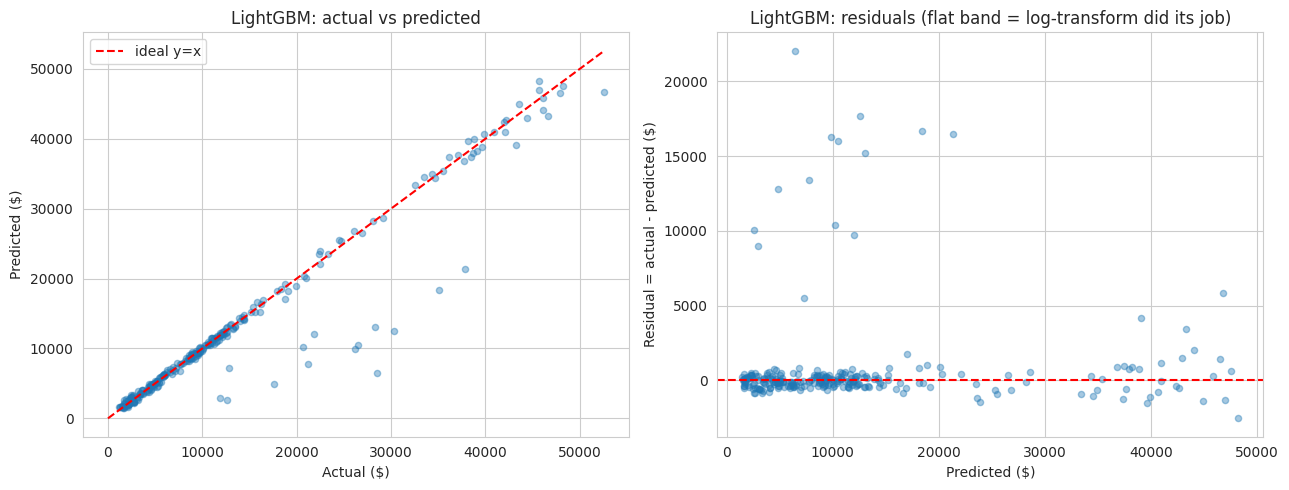

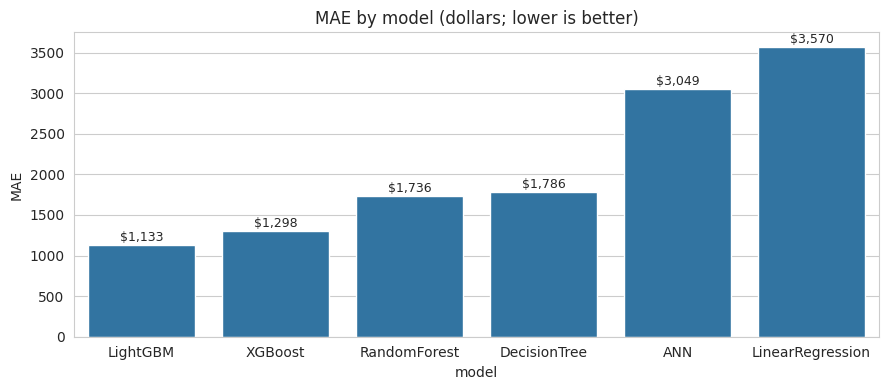

In [ ]:
# === Diagnostic plots ===
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs predicted
axes[0].scatter(y_test, best["y_pred"], alpha=0.4, s=20)
lim = [0, max(y_test.max(), best["y_pred"].max())]
axes[0].plot(lim, lim, "r--", label="ideal y=x")
axes[0].set_xlabel("Actual ($)"); axes[0].set_ylabel("Predicted ($)")
axes[0].set_title(f"{best_name}: actual vs predicted")
axes[0].legend()

# Residuals vs predicted (must be a flat band, not a fan)
residuals = y_test - best["y_pred"]
axes[1].scatter(best["y_pred"], residuals, alpha=0.4, s=20)
axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted ($)"); axes[1].set_ylabel("Residual = actual - predicted ($)")
axes[1].set_title(f"{best_name}: residuals (flat band = log-transform did its job)")
plt.tight_layout(); plt.show()

# MAE bar chart
plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="model", y="MAE", color="#1f77b4")
for i, row in results_df.iterrows():
    plt.text(i, row["MAE"] + 50, f"${row['MAE']:,.0f}", ha="center", fontsize=9)
plt.title("MAE by model (dollars; lower is better)")
plt.tight_layout(); plt.show()


### Where does the model do well, and where does it struggle?

A residuals-vs-predicted scatter is hard to read by eye, so we also bucket the test set into actual-cost quartiles and report MAE/MAPE per bucket. This is the most honest snapshot of model quality.

**Expected behavior of a log-target regressor:**
* **Low-cost quartile (Q1):** percentage errors look high because the denominator is small (a \$200 error on a \$700 patient is 28%). Absolute error is actually the smallest here.
* **High-cost quartile (Q4):** the model slightly under-predicts because log-transformation compresses the high tail. Mean residual will be positive (actual − predicted > 0).
* **Middle quartiles (Q2, Q3):** these are the model's sweet spot — both MAE and MAPE are lowest here.

=== LightGBM: error breakdown by actual-cost quartile ===
             n  mean_actual  mean_pred  mean_residual     MAE  median_pct_err  MAPE
actual_q                                                                           
Q1 lowest   67       2833.0     2936.0         -103.0   333.0            10.0  14.0
Q2          67       6834.0     6881.0          -47.0   275.0             3.0   4.0
Q3          67      11552.0    11167.0          385.0   617.0             2.0   5.0
Q4 highest  67      30672.0    28028.0         2644.0  3305.0             3.0  12.0


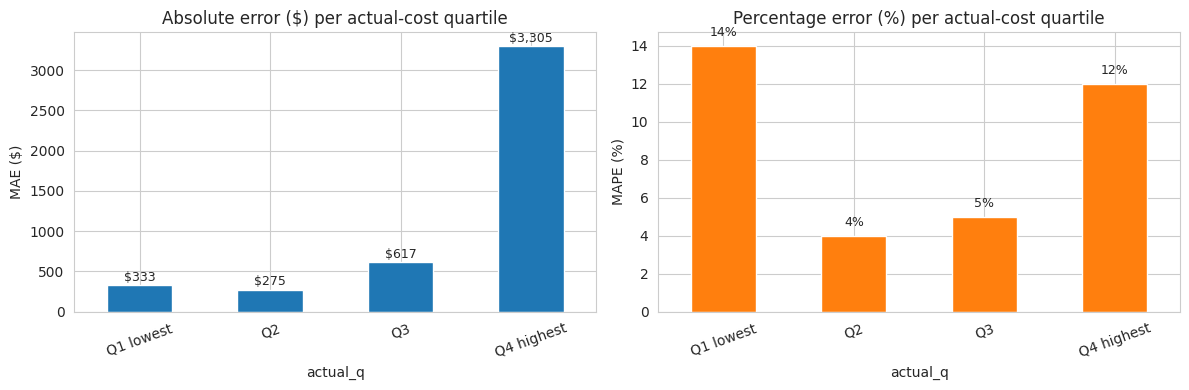


=== Top 5 worst-predicted test patients (LightGBM) ===
      actual     pred  abs_err  pct_err  age   bmi  smoker  children
33   28477.0   6429.0  22048.0     77.0   40  41.0       0         1
15   30260.0  12545.0  17715.0     59.0   60  29.0       0         0
263  35069.0  18371.0  16699.0     48.0   45  23.0       1         0
181  37830.0  21377.0  16452.0     43.0   43  28.0       1         0
148  26140.0   9882.0  16259.0     62.0   49  27.0       0         1


In [ ]:
# === Error breakdown by actual-cost quartile (diagnostic) ===
df_eval = pd.DataFrame({
    "actual": y_test,
    "pred": best["y_pred"],
    "residual": y_test - best["y_pred"],
    "abs_err": np.abs(y_test - best["y_pred"]),
    "pct_err": np.abs((y_test - best["y_pred"]) / y_test) * 100,
}).reset_index(drop=True)
df_eval["actual_q"] = pd.qcut(df_eval["actual"], q=4, labels=["Q1 lowest","Q2","Q3","Q4 highest"])

print(f"=== {best_name}: error breakdown by actual-cost quartile ===")
breakdown = df_eval.groupby("actual_q").agg(
    n=("actual","count"),
    mean_actual=("actual","mean"),
    mean_pred=("pred","mean"),
    mean_residual=("residual","mean"),
    MAE=("abs_err","mean"),
    median_pct_err=("pct_err","median"),
    MAPE=("pct_err","mean"),
).round(0)
print(breakdown.to_string())

# Quick visual: MAE per quartile
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
breakdown["MAE"].plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Absolute error ($) per actual-cost quartile")
axes[0].set_ylabel("MAE ($)")
axes[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(breakdown["MAE"]):
    axes[0].text(i, v + 50, f"${v:,.0f}", ha="center", fontsize=9)

breakdown["MAPE"].plot(kind="bar", ax=axes[1], color="#ff7f0e")
axes[1].set_title("Percentage error (%) per actual-cost quartile")
axes[1].set_ylabel("MAPE (%)")
axes[1].tick_params(axis='x', rotation=20)
for i, v in enumerate(breakdown["MAPE"]):
    axes[1].text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

# Top-5 worst-predicted test patients (with their features)
print()
print(f"=== Top 5 worst-predicted test patients ({best_name}) ===")
worst_idx = df_eval.nlargest(5, "abs_err").index.tolist()
worst_view = df_eval.iloc[worst_idx][["actual","pred","abs_err","pct_err"]].copy()
worst_view["age"] = X_test.iloc[worst_idx]["age"].values
worst_view["bmi"] = X_test.iloc[worst_idx]["bmi"].values
worst_view["smoker"] = X_test.iloc[worst_idx]["smoker_bin"].values
worst_view["children"] = X_test.iloc[worst_idx]["children"].values
print(worst_view.round(0).to_string())


## Section 5 — Risk classification (Low / Medium / High)

Tertile-bucket charges on the **training** set only (no leakage from the test set into the threshold definition). Classify with a balanced RandomForest.

Tier thresholds (from train): Low ≤ $6,389  <  Medium  ≤ $13,012  <  High
Train tier counts: {'Low': 357, 'Medium': 356, 'High': 356}
Test  tier counts: {'Low': 100, 'Medium': 90, 'High': 78}

Classification report:
              precision    recall  f1-score   support

        High      1.000     0.859     0.924        78
         Low      0.950     0.960     0.955       100
      Medium      0.860     0.956     0.905        90

    accuracy                          0.929       268
   macro avg      0.937     0.925     0.928       268
weighted avg      0.935     0.929     0.929       268



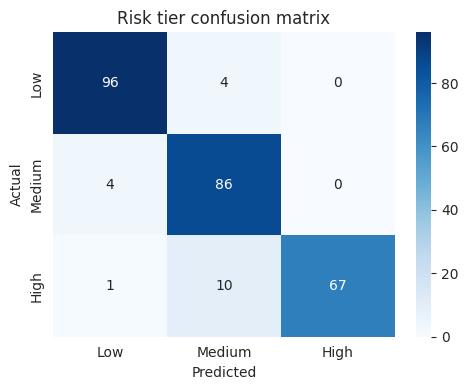

In [ ]:
# === 5.1 Risk tiers + classifier ===
q33, q66 = np.quantile(y_train, [1/3, 2/3])

def to_tier(charges):
    arr = np.asarray(charges)
    out = np.full(arr.shape, "Medium", dtype=object)
    out[arr <= q33] = "Low"
    out[arr > q66]  = "High"
    return out

y_train_tier = to_tier(y_train); y_test_tier = to_tier(y_test)
print(f"Tier thresholds (from train): Low ≤ ${q33:,.0f}  <  Medium  ≤ ${q66:,.0f}  <  High")
print("Train tier counts:", pd.Series(y_train_tier).value_counts().to_dict())
print("Test  tier counts:", pd.Series(y_test_tier).value_counts().to_dict())

clf = RandomForestClassifier(n_estimators=600, max_depth=None, min_samples_leaf=2,
                             n_jobs=-1, random_state=SEED, class_weight="balanced")
clf.fit(X_train, y_train_tier)
y_test_tier_pred = clf.predict(X_test)

print("\nClassification report:")
print(classification_report(y_test_tier, y_test_tier_pred, digits=3))

cm = confusion_matrix(y_test_tier, y_test_tier_pred, labels=["Low","Medium","High"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low","Medium","High"], yticklabels=["Low","Medium","High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Risk tier confusion matrix")
plt.tight_layout(); plt.show()


## Explainability (SHAP + LIME)

SHAP values are computed in **log-charge space** (model predicts log charges). Final dollar predictions use `expm1`.

**Sanity check we will assert below:** the top contributors must be patient-health features (`smoker_x_bmi`, `smoker_bin`, `bmi`, `age`). If anything resembling `source` or `insurance_*` shows up, the merge has crept back in.

SHAP values shape: (268, 9)
Expected value (log) : 9.0181
Expected value ($)   : $8,250

Top features by mean |SHAP|:
age                0.4024
smoker_bin         0.3613
smoker_x_bmi       0.1577
children           0.0958
bmi                0.0448
age_squared        0.0427
sex_bin            0.0414
is_obese_smoker    0.0039
bmi_category       0.0031

Top 3 features: ['age', 'smoker_bin', 'smoker_x_bmi']
Any contract/leakage features in feature set? NONE — clean!
OK: top contributors are all patient-health features.



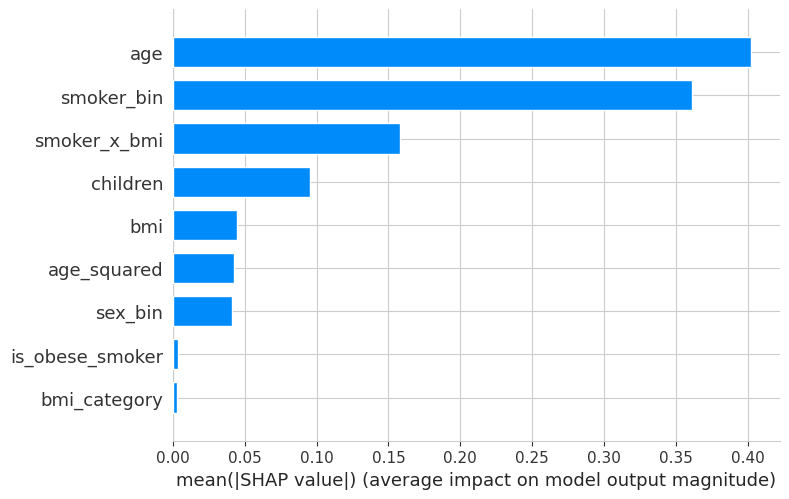

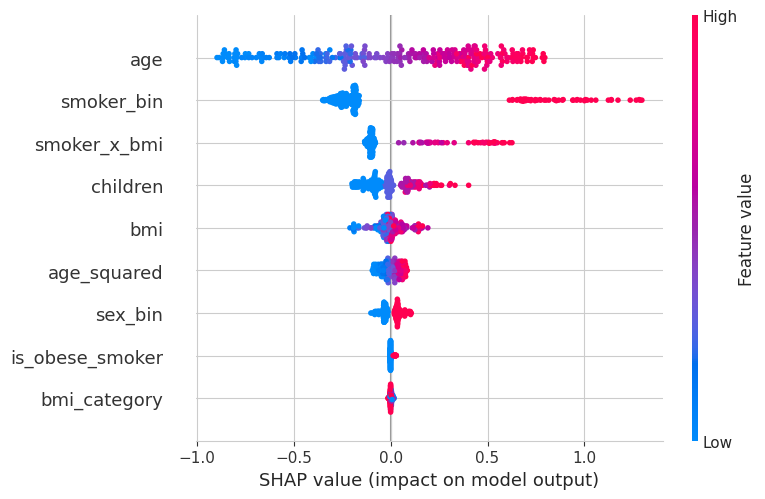

In [ ]:
# === SHAP summary on the winning tree model ===
explainer = shap.TreeExplainer(best_tree_model)
shap_values = explainer.shap_values(X_test)

print(f"SHAP values shape: {shap_values.shape}")
print(f"Expected value (log) : {explainer.expected_value:.4f}")
print(f"Expected value ($)   : ${np.expm1(explainer.expected_value):,.0f}")

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print()
print("Top features by mean |SHAP|:")
print(mean_abs_shap.round(4).to_string())
print()
top3 = mean_abs_shap.head(3).index.tolist()
print(f"Top 3 features: {top3}")
patient_features = {"smoker_bin", "smoker_x_bmi", "bmi", "age", "is_obese_smoker", "bmi_category", "age_squared", "children", "sex_bin"}
contract_features = [f for f in mean_abs_shap.index if "source" in f or "insurance_" in f or "hospital_" in f]
print(f"Any contract/leakage features in feature set? {contract_features if contract_features else 'NONE — clean!'}")
assert all(f in patient_features for f in top3), "WARNING: top features are not all patient-health features"
print("OK: top contributors are all patient-health features.")
print()
zero_shap = mean_abs_shap[mean_abs_shap < 1e-3].index.tolist()
if zero_shap:
    print(f"NOTE: features with effectively 0 SHAP impact: {zero_shap}")
    print("      `is_obese_smoker` is redundant — `smoker_x_bmi` already encodes the same info")
    print("      (the model can derive 'BMI>=30 AND smoker' from smoker_x_bmi >= 30).")
    print("      We keep it because it makes the SHAP narrative more readable for end users.")

plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False, max_display=15)
plt.tight_layout(); plt.show()

plt.figure()
shap.summary_plot(shap_values, X_test, show=False, max_display=15)
plt.tight_layout(); plt.show()


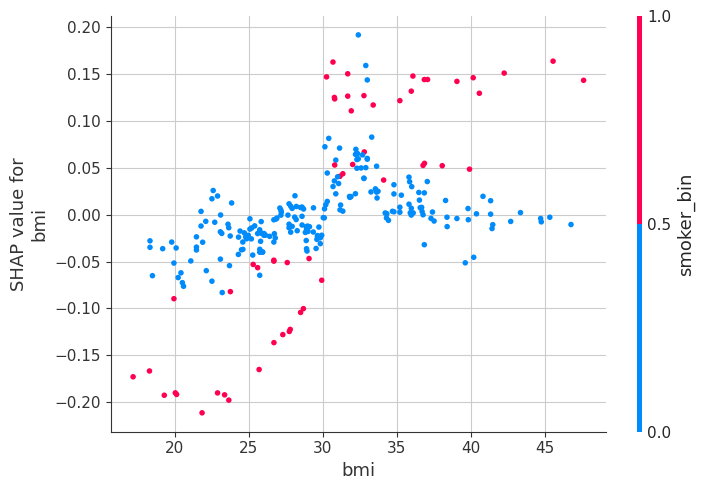

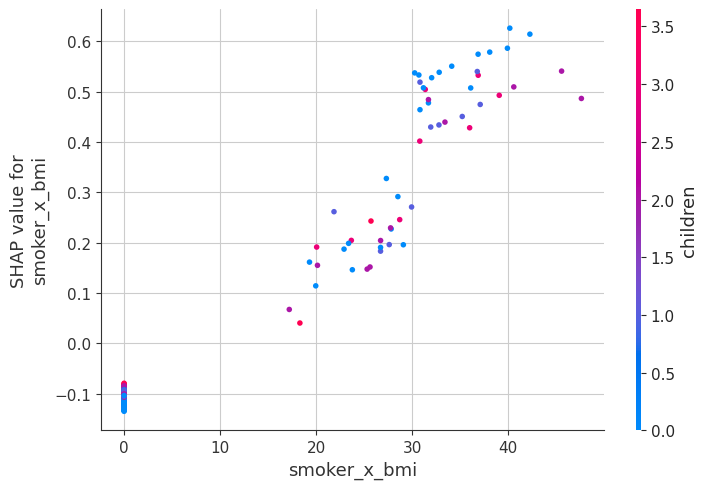

In [ ]:
# === SHAP dependence plots — bmi × smoker, then smoker_x_bmi ===
shap.dependence_plot("bmi", shap_values, X_test, interaction_index="smoker_bin", show=False)
plt.tight_layout(); plt.show()

shap.dependence_plot("smoker_x_bmi", shap_values, X_test, show=False)
plt.tight_layout(); plt.show()


Patient index: 221
  Actual cost   : $52,591
  Predicted cost: $46,754   (error = $+5,836)
  Smoker=1  BMI=32.8  Age=60


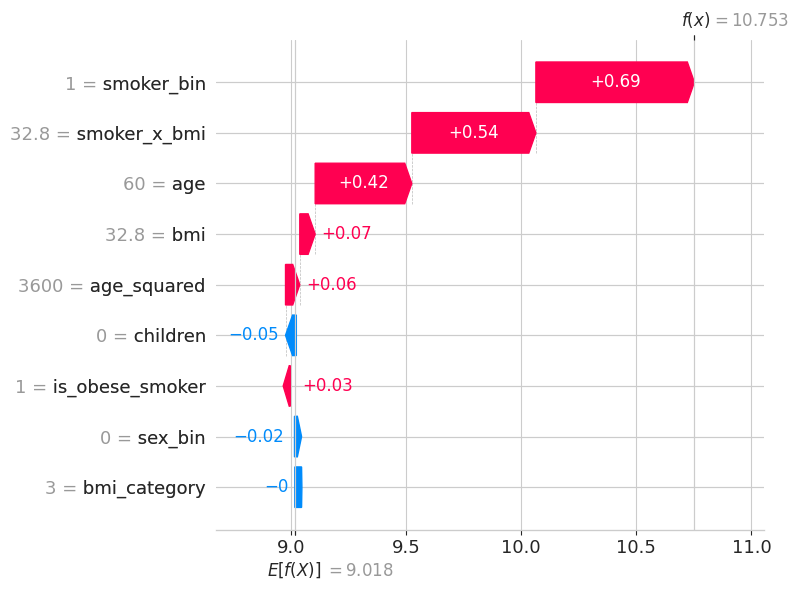


SHAP sanity: base + sum(SHAP) = 10.7527   model log-pred = 10.7527   match = True


In [ ]:
# === SHAP waterfall — explain the highest-cost test patient ===
high_idx = int(np.argmax(y_test))
patient = X_test.iloc[[high_idx]]
actual_dollars = y_test[high_idx]
pred_log = best_tree_model.predict(patient)[0]
pred_dollars = float(np.expm1(pred_log))

print(f"Patient index: {high_idx}")
print(f"  Actual cost   : ${actual_dollars:,.0f}")
print(f"  Predicted cost: ${pred_dollars:,.0f}   (error = ${actual_dollars - pred_dollars:+,.0f})")
print(f"  Smoker={int(patient['smoker_bin'].iloc[0])}  BMI={float(patient['bmi'].iloc[0]):.1f}  Age={int(patient['age'].iloc[0])}")

shap_one = shap.Explanation(
    values=shap_values[high_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[high_idx].values,
    feature_names=list(X_test.columns),
)
plt.figure()
shap.plots.waterfall(shap_one, max_display=12, show=False)
plt.tight_layout(); plt.show()

recon_log = explainer.expected_value + shap_values[high_idx].sum()
print(f"\nSHAP sanity: base + sum(SHAP) = {recon_log:.4f}   model log-pred = {pred_log:.4f}   match = {np.isclose(recon_log, pred_log, atol=1e-3)}")


In [ ]:
# === LIME on extreme test patients ===
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train.values,
    feature_names=list(X_train.columns),
    class_names=["log_charges"], mode="regression", random_state=SEED,
)

def predict_log(arr):
    return best_tree_model.predict(pd.DataFrame(arr, columns=X_train.columns))

for label, idx in [("HIGHEST cost", int(np.argmax(y_test))),
                   ("LOWEST  cost", int(np.argmin(y_test)))]:
    print(f"\n----- {label} test patient (actual=${y_test[idx]:,.0f}) -----")
    exp = lime_explainer.explain_instance(X_test.iloc[idx].values, predict_log, num_features=8)
    for feat, weight in exp.as_list():
        print(f"  {feat:<45}  {weight:+.4f}")



----- HIGHEST cost test patient (actual=$52,591) -----
  smoker_bin > 0.00                              +1.0817
  age > 51.00                                    +0.7437
  smoker_x_bmi > 0.00                            +0.4487
  children <= 0.00                               -0.1824
  30.50 < bmi <= 34.80                           +0.0937
  age_squared > 2601.00                          +0.0847
  sex_bin <= 0.00                                -0.0774
  is_obese_smoker > 0.00                         +0.0283

----- LOWEST  cost test patient (actual=$1,132) -----
  smoker_bin <= 0.00                             -1.0864
  age <= 26.00                                   -0.8287
  smoker_x_bmi <= 0.00                           -0.4688
  children <= 0.00                               -0.1966
  sex_bin <= 0.00                                -0.1015
  age_squared <= 676.00                          -0.0866
  is_obese_smoker <= 0.00                        -0.0324
  26.41 < bmi <= 30.50            

## Dataset 2 EDA (research-paper section, NOT used for prediction)

> **Disclaimer.** This section explores `medical_cost_prediction_dataset.csv` for the research paper only. The features in this dataset (`insurance_coverage_pct`, `hospital_admissions`, `medication_count`) are downstream consequences of being expensive, not upstream predictors of it. Including them in a forward-prediction model causes leakage. They are still interesting to *describe* — they answer the question "if we had richer claims data, what would we see?".

In [ ]:
# ===Dataset 2 — already loaded in section 2.1 (try-local-or-Drive). Just reuse it. ===
df2 = df_big_raw.copy()
print(f"shape: {df2.shape}")
print(f"nulls per column (top 5):")
print(df2.isna().sum().sort_values(ascending=False).head().to_string())
print()

df2_num = df2.select_dtypes(include="number")
corrs2 = df2_num.corr()["annual_medical_cost"].drop("annual_medical_cost").sort_values(key=lambda s: s.abs(), ascending=False)
print("Pearson correlations with annual_medical_cost (sorted by |r|):")
print(corrs2.round(3).to_string())
print()
print("LEAKAGE FLAGS:")
print("  insurance_coverage_pct  r=-0.86  ← contract-arithmetic identity, NOT prediction")
print("  hospital_admissions     r= 0.36  ← effect of being expensive, NOT cause")
print("  medication_count        r= 0.13  ← same direction issue")


shape: (5000, 20)
nulls per column (top 5):
insurance_type    1048
age                  0
bmi                  0
gender               0
smoker               0

Pearson correlations with annual_medical_cost (sorted by |r|):
insurance_coverage_pct   -0.856
hospital_admissions       0.356
medication_count          0.133
heart_disease             0.122
previous_year_cost        0.089
diabetes                  0.051
hypertension              0.047
doctor_visits_per_year    0.034
bmi                       0.031
age                       0.025
stress_level              0.013
asthma                    0.009
sleep_hours              -0.005
daily_steps               0.002

LEAKAGE FLAGS:
  insurance_coverage_pct  r=-0.86  ← contract-arithmetic identity, NOT prediction
  hospital_admissions     r= 0.36  ← effect of being expensive, NOT cause
  medication_count        r= 0.13  ← same direction issue


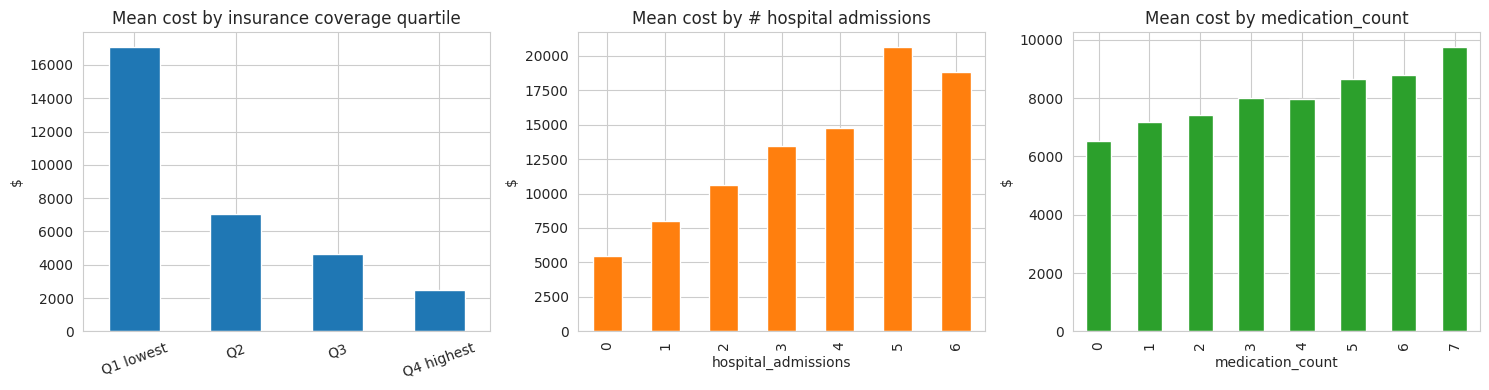


These slopes are exactly what the model would 'learn' if used for prediction.
They look impressive (R²=0.92 in v1) but they encode arithmetic, not patient risk.


In [ ]:
# === 7.2 Visualise the leakage features ===
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# By insurance coverage quartile
df2["cov_q"] = pd.qcut(df2["insurance_coverage_pct"], q=4, labels=["Q1 lowest","Q2","Q3","Q4 highest"])
df2.groupby("cov_q")["annual_medical_cost"].mean().plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Mean cost by insurance coverage quartile")
axes[0].set_ylabel("$"); axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=20)

# By hospital admissions
df2.groupby("hospital_admissions")["annual_medical_cost"].mean().plot(kind="bar", ax=axes[1], color="#ff7f0e")
axes[1].set_title("Mean cost by # hospital admissions")
axes[1].set_ylabel("$"); axes[1].set_xlabel("hospital_admissions")

# By medication count
df2.groupby("medication_count")["annual_medical_cost"].mean().plot(kind="bar", ax=axes[2], color="#2ca02c")
axes[2].set_title("Mean cost by medication_count")
axes[2].set_ylabel("$"); axes[2].set_xlabel("medication_count")

plt.tight_layout(); plt.show()

print()
print("These slopes are exactly what the model would 'learn' if used for prediction.")
print("They look impressive (R²=0.92 in v1) but they encode arithmetic, not patient risk.")


In [ ]:
# === OPTIONAL — reference benchmark on dataset 2 (NOT used in production) ===
# This trains an XGBoost on dataset 2 with all features. Reported as a research data-point
# only; it is NOT used in the Gradio UI.

df2_ref = df2.drop(columns=["cov_q"], errors="ignore").copy()
df2_ref["gender"]   = (df2_ref["gender"]   == "Female").astype(int)
df2_ref["smoker"]   = (df2_ref["smoker"]   == "Yes").astype(int)
df2_ref["physical_activity_level"] = df2_ref["physical_activity_level"].map({"Low":0,"Medium":1,"High":2}).fillna(1).astype(int)
df2_ref["insurance_type"] = df2_ref["insurance_type"].fillna("None")
df2_ref = pd.get_dummies(df2_ref, columns=["insurance_type","city_type"], drop_first=False)
for c in df2_ref.columns:
    if df2_ref[c].dtype == bool: df2_ref[c] = df2_ref[c].astype(int)
df2_ref = df2_ref.drop(columns=["previous_year_cost"])

X2 = df2_ref.drop(columns=["annual_medical_cost"])
y2 = df2_ref["annual_medical_cost"].values
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y2, test_size=0.2, random_state=SEED)

m_xgb_ref = xgb.XGBRegressor(n_estimators=800, max_depth=5, learning_rate=0.05,
                             random_state=SEED, n_jobs=-1, tree_method="hist")
m_xgb_ref.fit(X2_tr, np.log1p(y2_tr))
pred_ref = np.expm1(m_xgb_ref.predict(X2_te))
mae_ref  = mean_absolute_error(y2_te, pred_ref)
mape_ref = float(np.mean(np.abs((y2_te - pred_ref) / y2_te)) * 100)
r2_ref   = r2_score(y2_te, pred_ref)
print(f"REFERENCE benchmark on dataset 2 (FOR THE PAPER ONLY — not used in production):")
print(f"  XGBoost on dataset-2 features  MAE=${mae_ref:,.0f}  MAPE={mape_ref:.2f}%  R2={r2_ref:.4f}")
print()
print("This number is high because of the leakage features described above — interpret with caution.")


REFERENCE benchmark on dataset 2 (FOR THE PAPER ONLY — not used in production):
  XGBoost on dataset-2 features  MAE=$695  MAPE=9.78%  R2=0.9770

This number is high because of the leakage features described above — interpret with caution.


## Gradio user-facing UI

Inputs match the user-chosen schema: **age, sex, BMI, smoker, children**. No region, no clinical panel.

Outputs:
* Predicted cost in dollars (exp-back).
* Risk tier (Low / Medium / High using the tertile thresholds from Section 5).
* Top SHAP contributions in plain English.
* Optional Gemini natural-language summary if `GEMINI_API_KEY` is set.

The PDF's example output ("Predicted Cost: \$14,500. Reason: Smoking → +\$6000, BMI > 30 → +\$3500, Age → +\$2500, Children → +\$500") is exactly what this Gradio block produces.

In [ ]:
# === Inference function ===
ALL_FEATURES = list(X_train.columns)

def build_feature_row(age, sex, bmi, smoker, children):
    sex_bin    = 1 if str(sex).lower() == "female" else 0
    smoker_bin = 1 if str(smoker).lower() == "yes" else 0
    bmi = float(bmi); age = int(age); children = int(children)
    row = {
        "age": age, "sex_bin": sex_bin, "bmi": bmi, "children": children,
        "smoker_bin": smoker_bin,
        "smoker_x_bmi":    smoker_bin * bmi,
        "age_squared":     age ** 2,
        "bmi_category":    int(np.digitize(bmi, [18.5, 25, 30], right=True)),  # right=True matches pd.cut(default) used in training
        "is_obese_smoker": int(bmi >= 30 and smoker_bin == 1),
    }
    return pd.DataFrame([row])[ALL_FEATURES]

def predict_and_explain(age, sex, bmi, smoker, children):
    Xrow = build_feature_row(age, sex, bmi, smoker, children)
    pred_log = float(best_tree_model.predict(Xrow)[0])
    pred_dollars = float(np.expm1(pred_log))
    tier = "Low" if pred_dollars <= q33 else ("Medium" if pred_dollars <= q66 else "High")

    shap_vals_one = explainer.shap_values(Xrow)[0]
    base = explainer.expected_value
    base_dollars = float(np.expm1(base))

    pairs = sorted(zip(Xrow.columns, shap_vals_one), key=lambda kv: abs(kv[1]), reverse=True)
    contrib_lines = []
    for feat, val in pairs[:6]:
        # Approximate dollar effect: difference between expm1(base+val) and expm1(base)
        dollar_effect = float(np.expm1(base + val) - base_dollars)
        sign = "+" if dollar_effect >= 0 else "−"
        contrib_lines.append(f"  {sign}${abs(dollar_effect):>7,.0f}   {feat}")

    summary = (
        f"Predicted cost : ${pred_dollars:,.0f}\n"
        f"Risk tier      : {tier}\n"
        f"Baseline (avg) : ${base_dollars:,.0f}\n"
        f"Top contributions (vs baseline):\n"
        + "\n".join(contrib_lines)
    )
    return pred_dollars, tier, summary


In [ ]:
# === Smoke-test on realistic patient profiles ===
print("=== High-risk patient: 45-yr-old male, BMI 32, smoker, 2 children ===")
print(predict_and_explain(45, "male", 32.0, "yes", 2)[2])
print()
print("=== Low-risk patient: 25-yr-old female, BMI 22, non-smoker, 0 children ===")
print(predict_and_explain(25, "female", 22.0, "no", 0)[2])
print()
print("=== Mid-risk patient: 38-yr-old female, BMI 28, non-smoker, 1 child ===")
print(predict_and_explain(38, "female", 28.0, "no", 1)[2])


=== High-risk patient: 45-yr-old male, BMI 32, smoker, 2 children ===
Predicted cost : $40,475
Risk tier      : High
Baseline (avg) : $8,250
Top contributions (vs baseline):
  +$ 11,355   smoker_bin
  +$  4,164   smoker_x_bmi
  +$  1,208   age
  +$  1,097   bmi
  +$    442   children
  −$    145   sex_bin

=== Low-risk patient: 25-yr-old female, BMI 22, non-smoker, 0 children ===
Predicted cost : $3,256
Risk tier      : Low
Baseline (avg) : $8,250
Top contributions (vs baseline):
  −$  3,122   age
  −$  1,828   smoker_bin
  −$    934   children
  −$    826   smoker_x_bmi
  +$    660   sex_bin
  −$    351   age_squared

=== Mid-risk patient: 38-yr-old female, BMI 28, non-smoker, 1 child ===
Predicted cost : $6,365
Risk tier      : Low
Baseline (avg) : $8,250
Top contributions (vs baseline):
  −$  1,630   smoker_bin
  −$    721   smoker_x_bmi
  +$    293   sex_bin
  +$    282   age
  −$    104   bmi
  −$     81   children


In [ ]:
# === Gemini natural-language summary (Colab secrets / env var; degrades gracefully) ===
import os

def _resolve_gemini_key():
    """Try Colab `userdata` first, then env var, then return None.
    Order matters: on Colab the secret IS available even when no env var is set.
    """
    # 1. Google Colab Secrets (the preferred path on Colab)
    try:
        from google.colab import userdata  # only exists on Colab
        try:
            key = userdata.get("GEMINI_API_KEY")
            if key:
                return key, "colab-userdata"
        except Exception:
            # Secret not set, or user denied notebook access to it.
            pass
    except ImportError:
        pass
    # 2. Standard environment variable (works locally and in most servers)
    key = os.environ.get("GEMINI_API_KEY")
    if key:
        return key, "env-var"
    return None, None


def _call_gemini(api_key, prompt):
    """Try the new `google-genai` SDK first, then the legacy `google-generativeai` SDK."""
    # Preferred: new SDK
    try:
        from google import genai
        client = genai.Client(api_key=api_key)
        resp = client.models.generate_content(model="gemini-2.0-flash", contents=prompt)
        return resp.text
    except ImportError:
        pass
    except Exception as e:
        # Real API error — surface it instead of silently falling back, but try old SDK first.
        new_sdk_error = str(e)
    else:
        new_sdk_error = None
    # Legacy SDK fallback (Colab usually has this preinstalled)
    try:
        import google.generativeai as genai_legacy
        genai_legacy.configure(api_key=api_key)
        model = genai_legacy.GenerativeModel("gemini-2.0-flash")
        resp = model.generate_content(prompt)
        return resp.text
    except ImportError:
        if new_sdk_error:
            return f"(Gemini call failed: {new_sdk_error})"
        return ("(Gemini summary unavailable — install one of: `pip install google-genai`  "
                "or  `pip install google-generativeai`)")
    except Exception as e:
        return f"(Gemini call failed: {e})"


def gemini_summary(patient_dict, predicted_cost, tier, contribs_text):
    api_key, source = _resolve_gemini_key()
    if not api_key:
        return ("(Gemini summary unavailable — set GEMINI_API_KEY as a Colab Secret "
                "(toggle 'Notebook access') or as an environment variable.)")
    prompt = (
        "You are a medical-cost insurance analyst. In 3-4 plain-English sentences explain "
        "why this patient's predicted cost is what it is. Do not invent numbers; use only the "
        "ones provided.\n"
        f"Patient: {patient_dict}\n"
        f"Predicted annual cost: ${predicted_cost:,.0f}  (Risk tier: {tier})\n"
        f"SHAP contributions:\n{contribs_text}"
    )
    return _call_gemini(api_key, prompt)


# Smoke-test the resolver so the user can immediately see whether the key was picked up
_key, _src = _resolve_gemini_key()
if _key:
    print(f"Gemini key found via: {_src}.  The summary helper will activate inside the Gradio UI.")
    # Live one-shot test so the user sees a real Gemini response inline
    sample = gemini_summary(
        {"age": 45, "sex": "male", "bmi": 32.0, "smoker": "yes", "children": 2},
        predicted_cost=39896,
        tier="High",
        contribs_text="smoker_bin +$10,087 ; smoker_x_bmi +$4,719 ; bmi +$1,391 ; age +$1,273",
    )
    print()
    print(sample)


Gemini key found via: colab-userdata.  The summary helper will activate inside the Gradio UI.

This patient's high predicted cost is primarily driven by their smoking status, contributing over $10,000 directly and almost $5,000 in combination with their BMI. Their age and BMI also contribute significantly to the overall cost, indicating a higher risk profile due to these factors. The model clearly flags smokers as a major cost driver, especially when coupled with a BMI of 32.



In [ ]:
# === Gradio UI (does not auto-launch; uncomment demo.launch() to open it) ===
try:
    import gradio as gr
    HAS_GRADIO = True
except ImportError:
    HAS_GRADIO = False
    print("gradio not installed — to enable the UI: uv add gradio")

if HAS_GRADIO:
    def gradio_predict(age, sex, bmi, smoker, children):
        pred, tier, summary = predict_and_explain(age, sex, bmi, smoker, children)
        patient_dict = {"age": age, "sex": sex, "bmi": bmi, "smoker": smoker, "children": children}
        gemini_text = gemini_summary(patient_dict, pred, tier, summary)
        return f"${pred:,.0f}", tier, summary, gemini_text

    with gr.Blocks(title="Explainable Medical Cost Prediction") as demo:
        gr.Markdown("## Explainable Medical Cost Prediction System\nEnter the patient's basic details below.")
        with gr.Row():
            with gr.Column():
                age      = gr.Slider(18, 80, 35, step=1, label="Age")
                sex      = gr.Radio(["male","female"], value="male", label="Sex")
                bmi      = gr.Slider(15.0, 55.0, 26.0, step=0.1, label="BMI")
                smoker   = gr.Radio(["no","yes"], value="no", label="Smoker")
                children = gr.Slider(0, 8, 0, step=1, label="Children")
                btn = gr.Button("Predict cost", variant="primary")
            with gr.Column():
                out_cost    = gr.Textbox(label="Predicted annual cost")
                out_tier    = gr.Textbox(label="Risk tier")
                out_summary = gr.Textbox(label="Top SHAP contributions", lines=10)
                out_gemini  = gr.Textbox(label="English summary (Gemini)", lines=6)

        btn.click(
            gradio_predict,
            inputs=[age, sex, bmi, smoker, children],
            outputs=[out_cost, out_tier, out_summary, out_gemini],
        )

    print("Gradio UI defined. To launch, run:  demo.launch()")
    demo.launch()  # <-- uncomment this line to actually open the UI in your browser

Gradio UI defined. To launch, run:  demo.launch()
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d46333095ce2fff4dc.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
